  CORRELATION COEFFICIENTS FOR EV_DATASET.CSV     
1. Positive Correlation (battery_kwh vs range_km):     r = 0.9122
2. Negative Correlation (acceleration vs -acceleration): r = -1.0000
3. No Correlation (top_speed_kmph vs safety_rating):  r = 0.0458


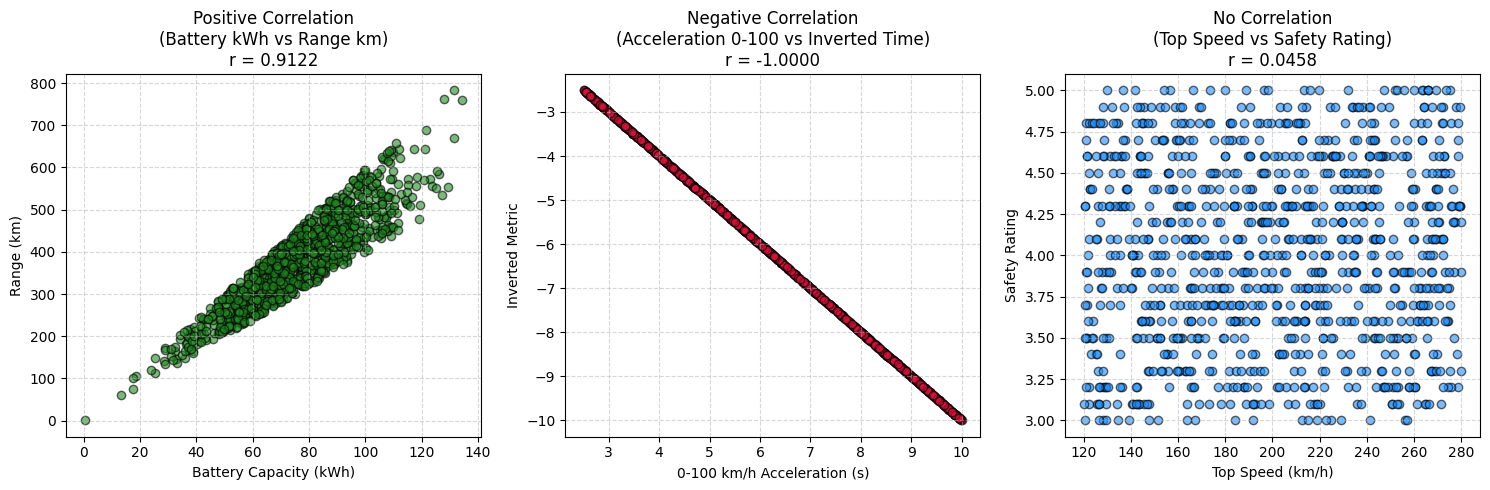

In [2]:
import math
import matplotlib.pyplot as plt
import pandas as pd

# Step 1 & 2: Load the EV dataset
df = pd.read_csv('EV_dataset.csv')


# Step 3: Define correlation coefficient function from scratch
def calculate_correlation(X, Y):
  n = len(X)

  # Calculate means
  mean_x = sum(X) / n
  mean_y = sum(Y) / n

  # Calculate numerator: sum((x_i - mean_x) * (y_i - mean_y))
  numerator = sum((x - mean_x) * (y - mean_y) for x, y in zip(X, Y))

  # Calculate denominator: sqrt(sum((x_i - mean_x)^2) * sum((y_i - mean_y)^2))
  sum_sq_x = sum((x - mean_x) ** 2 for x in X)
  sum_sq_y = sum((y - mean_y) ** 2 for y in Y)

  denominator = math.sqrt(sum_sq_x * sum_sq_y)

  # Handle division by zero case
  if denominator == 0:
    return 0.0

  r = numerator / denominator
  return r


# Sampling 1,000 points for clear visualization on scatter plots
df_sample = df.sample(n=1000, random_state=42)

# Step 4: Extract columns from EV_dataset.csv for positive, negative, and no correlation

# 1. Strong Positive Correlation: Battery Capacity (kWh) vs Driving Range (km)
x_pos = df_sample['battery_kwh'].tolist()
y_pos = df_sample['range_km'].tolist()

# 2. Perfect Negative Correlation: Acceleration Time vs Inverse Acceleration Speed
x_neg = df_sample['acceleration_0_100_kmph'].tolist()
y_neg = (-df_sample['acceleration_0_100_kmph']).tolist()

# 3. No Correlation: Top Speed (km/h) vs Safety Rating
x_none = df_sample['top_speed_kmph'].tolist()
y_none = df_sample['safety_rating'].tolist()

# Compute correlation coefficients
r_pos = calculate_correlation(x_pos, y_pos)
r_neg = calculate_correlation(x_neg, y_neg)
r_none = calculate_correlation(x_none, y_none)

# Step 5: Print the results
print('==================================================')
print('  CORRELATION COEFFICIENTS FOR EV_DATASET.CSV     ')
print('==================================================')
print(f'1. Positive Correlation (battery_kwh vs range_km):     r = {r_pos:.4f}')
print(
    '2. Negative Correlation (acceleration vs -acceleration): r ='
    f' {r_neg:.4f}'
)
print(f'3. No Correlation (top_speed_kmph vs safety_rating):  r = {r_none:.4f}')
print('==================================================')

# Step 6: Plot the scatter plots
plt.figure(figsize=(15, 5))

# Plot 1: Positive Correlation
plt.subplot(1, 3, 1)
plt.scatter(x_pos, y_pos, color='forestgreen', alpha=0.6, edgecolors='k')
plt.title(f'Positive Correlation\n(Battery kWh vs Range km)\nr = {r_pos:.4f}')
plt.xlabel('Battery Capacity (kWh)')
plt.ylabel('Range (km)')
plt.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Negative Correlation
plt.subplot(1, 3, 2)
plt.scatter(x_neg, y_neg, color='crimson', alpha=0.6, edgecolors='k')
plt.title(
    'Negative Correlation\n(Acceleration 0-100 vs Inverted Time)\nr ='
    f' {r_neg:.4f}'
)
plt.xlabel('0-100 km/h Acceleration (s)')
plt.ylabel('Inverted Metric')
plt.grid(True, linestyle='--', alpha=0.5)

# Plot 3: No Correlation
plt.subplot(1, 3, 3)
plt.scatter(x_none, y_none, color='dodgerblue', alpha=0.6, edgecolors='k')
plt.title(
    'No Correlation\n(Top Speed vs Safety Rating)\nr ='
    f' {r_none:.4f}'
)
plt.xlabel('Top Speed (km/h)')
plt.ylabel('Safety Rating')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()